# Decoding the Stay Economy — Exploratory Data Analysis & Visualization
**Airbnb London vs. Booking.com London**

This notebook runs on the outputs of `clean_and_align_full_script.ipynb`:
`airbnb_master.csv`, `booking_london_clean.csv`, `comparison_schema.csv`,
and (optionally) the aggregated calendar/reviews files.

Every chart below states explicitly:
1. **The business analytics question it answers**
2. **Why this specific chart type was chosen**
3. **Why the obvious alternative chart types were rejected**

This is deliberate — a chart chosen without justification is a common
reason EDA sections lose marks; picking the right chart for the right
question is itself part of the analysis.

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# --- Global plotting config: one consistent, professional look throughout ---
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["figure.figsize"] = (9, 5)

DATA_DIR = "../data/processed"   # adjust if your notebook sits elsewhere

## 1. Load Data

We load the already-cleaned outputs, not the raw files — EDA should run
on trusted, cleaned data, not repeat cleaning logic inside the notebook.

In [7]:
airbnb = pd.read_csv(f"{DATA_DIR}/airbnb_master.csv", low_memory=False)
booking = pd.read_csv(f"{DATA_DIR}/booking_london_clean.csv", low_memory=False)
comparison = pd.read_csv(f"{DATA_DIR}/comparison_schema.csv", low_memory=False)

print(f"Airbnb master:      {airbnb.shape}")
print(f"Booking.com clean:  {booking.shape}")
print(f"Comparison schema:  {comparison.shape}")

Airbnb master:      (61617, 45)
Booking.com clean:  (262298, 22)
Comparison schema:  (323915, 15)


## 1. Guest-Perceived Value by Host Portfolio Segment

**Business question:** Does guest-perceived value differ across listings run by hosts with different portfolio sizes, and which groups may warrant a closer review of listing accuracy, amenities, and price/value messaging? This motivates the next ML task: estimate `review_scores_value` from listing characteristics that do not include review outcomes.

**Chart chosen: Boxplot with mean markers (0–5 scale)**
The boxplot shows the distribution and median of value scores in each host segment, while a diamond marks the observed mean. The model uses listing characteristics to prioritize profiles more likely to receive lower value scores. The sample size is shown for each group so a difference is interpreted in light of how much evidence supports it. The full 0–5 scale is retained to avoid visually exaggerating small score gaps.

**Why not a bar chart of means alone:** it would hide the spread and ceiling clustering of ratings. The observed gap can guide an operational audit, but it does not establish that portfolio size causes ratings to differ.

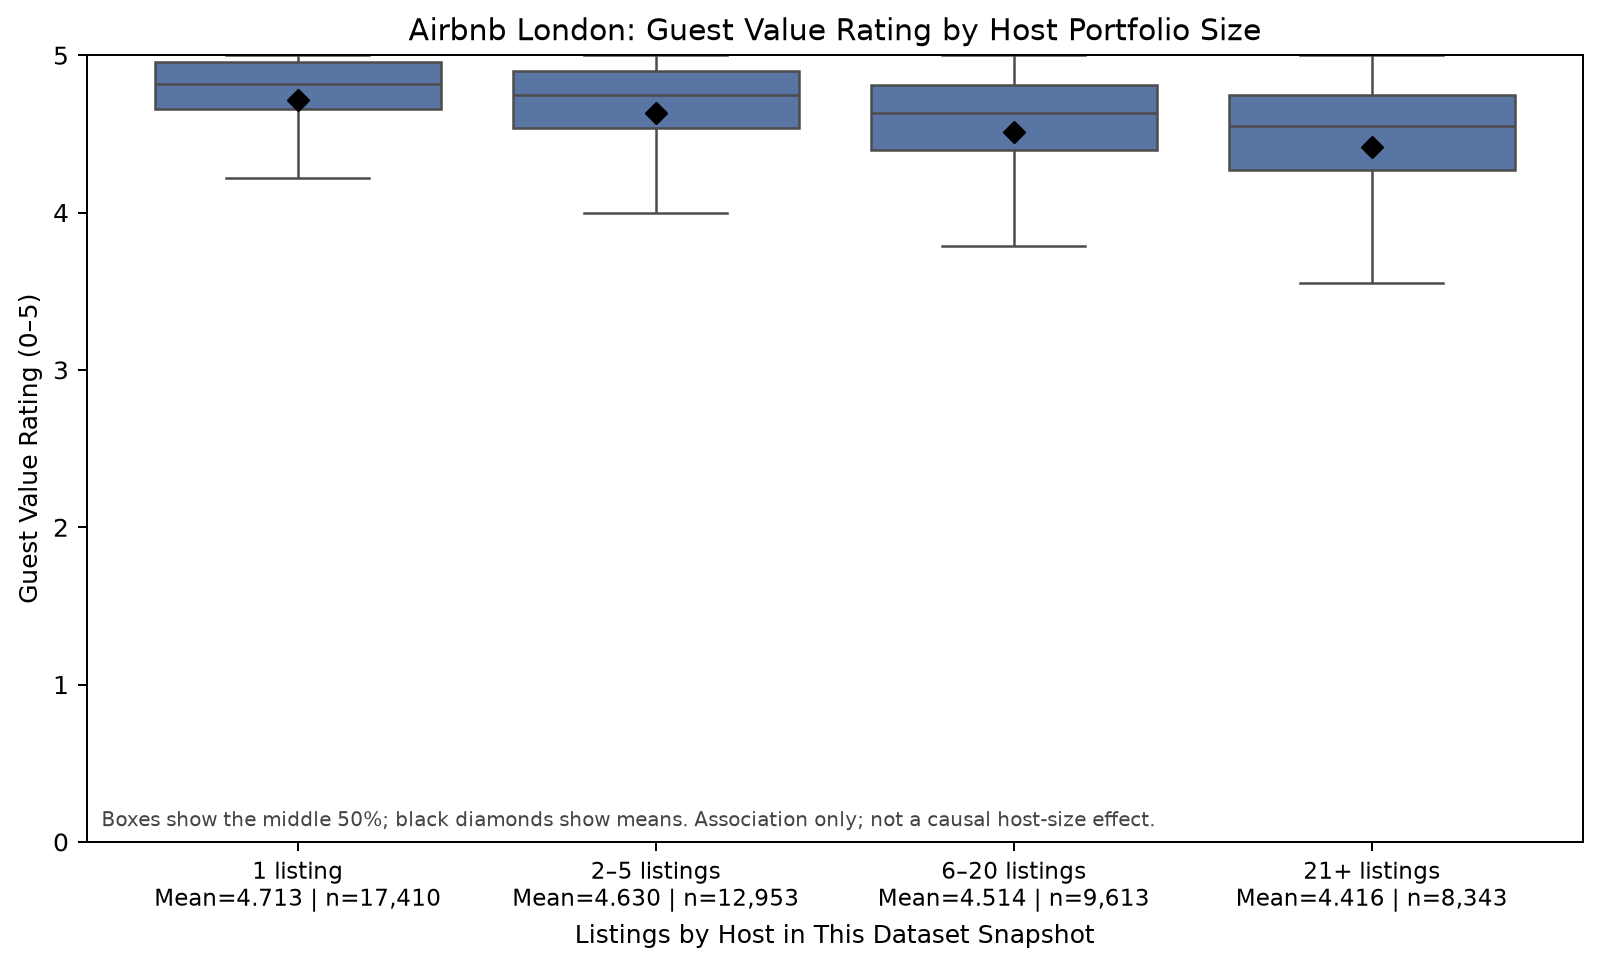

                        count   mean  median
host_portfolio_segment                      
1 listing               17410  4.713    4.82
2–5 listings            12953  4.630    4.75
6–20 listings            9613  4.514    4.63
21+ listings              8343  4.416    4.55


In [17]:
# Derive a chart-only host segment from the listing counts; do not expose host IDs.
value_df = airbnb[["id", "host_id", "review_scores_value"]].copy()
value_df["host_listing_count"] = value_df.groupby("host_id")["id"].transform("count")
value_df["host_portfolio_segment"] = pd.cut(
    value_df["host_listing_count"],
    bins=[0, 1, 5, 20, np.inf],
    labels=["1 listing", "2–5 listings", "6–20 listings", "21+ listings"],
    right=True,
)
value_df = value_df.dropna(subset=["review_scores_value", "host_portfolio_segment"])
segment_order = ["1 listing", "2–5 listings", "6–20 listings", "21+ listings"]
value_summary = value_df.groupby("host_portfolio_segment", observed=False)["review_scores_value"].agg(["count", "mean", "median"]).reindex(segment_order)

fig, ax = plt.subplots(figsize=(9, 5.5))
sns.boxplot(
    data=value_df, x="host_portfolio_segment", y="review_scores_value",
    order=segment_order, showfliers=False, color=sns.color_palette("deep")[0], ax=ax
)
tick_labels = []
for x, segment in enumerate(segment_order):
    mean_score = value_summary.loc[segment, "mean"]
    count = int(value_summary.loc[segment, "count"])
    ax.scatter(x, mean_score, marker="D", color="black", s=34, zorder=4)
    tick_labels.append(f"{segment}\nMean={mean_score:.3f} | n={count:,}")
ax.set_xticks(range(len(segment_order)), tick_labels)
ax.tick_params(axis="x", labelsize=9)
ax.set_title("Airbnb London: Guest Value Rating by Host Portfolio Size")
ax.set_xlabel("Listings by Host in This Dataset Snapshot")
ax.set_ylabel("Guest Value Rating (0–5)")
ax.set_ylim(0, 5)
ax.text(0.01, 0.02, "Boxes show the middle 50%; black diamonds show means. Association only; not a causal host-size effect.", transform=ax.transAxes, fontsize=8, color="#444444")
plt.tight_layout()
plt.savefig("../reports/value_rating_by_host_segment.png", dpi=180, bbox_inches="tight")
plt.show()

print(value_summary.round(3).to_string())

## 2. Price vs. Review Score vs. Review Count — Airbnb

**Business question:** Does charging more correlate with better reviews
(quality justifying price), or are cheaper listings actually rated
higher (value perception)? Does listing popularity (review count, a
proxy for booking volume) relate to price or quality?

**Chart chosen: Scatter plot with regression line, price vs. review
score, point size = review count**
A scatter plot is the only chart type that shows the *relationship*
between two continuous variables at the individual-listing level, and
encoding review count as point size adds a third variable without
needing a separate chart — this keeps three business-relevant signals
in one readable view.

**Why not a correlation heatmap alone:** a heatmap gives you the
correlation *coefficient* but hides the actual shape of the
relationship (linear? clustered? driven by outliers?) — we use both:
the scatter plot for shape, and a correlation matrix below for a full
multi-variable numeric summary.

**Sampling note:** with 60K+ points, a raw scatter plot becomes an
unreadable solid blob (overplotting). We sample 3,000 points for the
visual and keep the correlation calculation on the FULL dataset — the
chart is for pattern-reading, the number is for evidence.

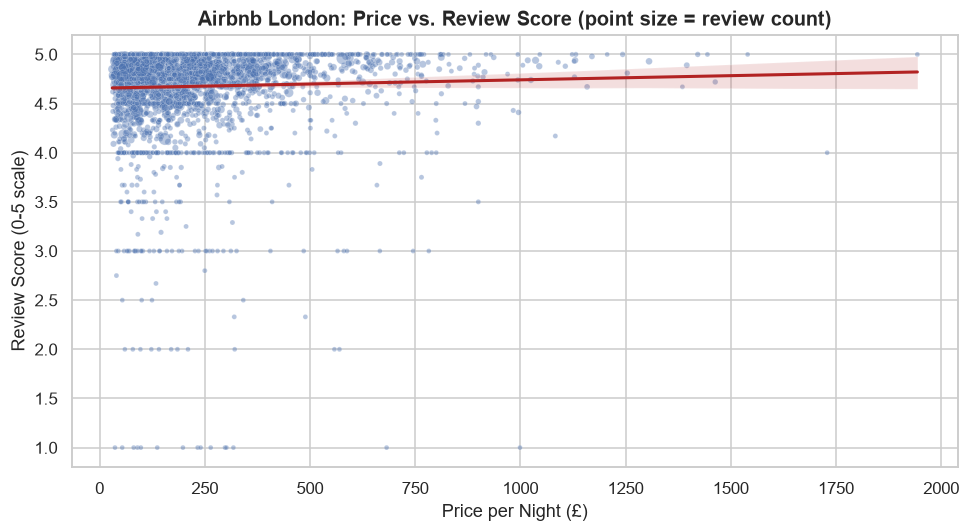

Correlation matrix (full dataset, not the plotting sample):
                      price  review_scores_rating  number_of_reviews
price                 1.000                 0.054             -0.094
review_scores_rating  0.054                 1.000              0.096
number_of_reviews    -0.094                 0.096              1.000


In [12]:
scatter_sample = airbnb.dropna(subset=["price", "review_scores_rating", "number_of_reviews"]).sample(
    n=min(3000, len(airbnb)), random_state=42
)

fig, ax = plt.subplots()
sns.scatterplot(
    data=scatter_sample, x="price", y="review_scores_rating",
    size="number_of_reviews", sizes=(10, 200), alpha=0.4, legend=False, ax=ax
)
sns.regplot(data=scatter_sample, x="price", y="review_scores_rating",
            scatter=False, ax=ax, color="firebrick", line_kws={"linewidth": 2})
ax.set_title("Airbnb London: Price vs. Review Score (point size = review count)")
ax.set_xlabel("Price per Night (£)")
ax.set_ylabel("Review Score (0-5 scale)")
plt.tight_layout()
plt.show()

full_corr = airbnb[["price", "review_scores_rating", "number_of_reviews"]].corr()
print("Correlation matrix (full dataset, not the plotting sample):")
print(full_corr.round(3))

## 3. Price Distribution by Property Type — Airbnb

**Business question:** What price tiers dominate the London Airbnb market,
and does price vary meaningfully by property type? This directly informs
a host's pricing strategy (where does my listing sit relative to the
market) and a guest's expectations (what should I expect to pay for a
given room type).

**Chart chosen: Boxplot (price by room_type)**
A boxplot shows the median, interquartile spread, and outliers
simultaneously across categories — exactly what's needed to compare
price *distributions* (not just averages) across 4 room types at once.

**Why not a bar chart of means:** a bar chart of average price would
hide the fact that price is heavily right-skewed (a few luxury listings
inflate the mean) — it would misrepresent what a "typical" listing costs.

**Why not a histogram:** a histogram works for one distribution at a
time; overlaying 4 histograms for 4 room types becomes visually
unreadable. Boxplots compress that comparison into one clean chart.

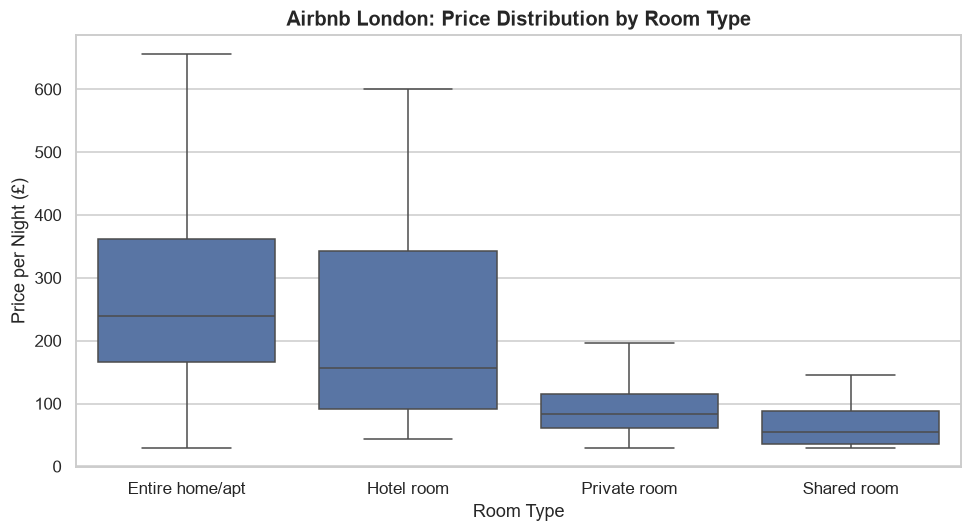

In [8]:
fig, ax = plt.subplots()
order = airbnb.groupby("room_type")["price"].median().sort_values(ascending=False).index
sns.boxplot(data=airbnb, x="room_type", y="price", order=order, showfliers=False, ax=ax)
ax.set_title("Airbnb London: Price Distribution by Room Type")
ax.set_xlabel("Room Type")
ax.set_ylabel("Price per Night (£)")
plt.tight_layout()
plt.show()

## 4. Price by Borough (Top 15) — Airbnb

**Business question:** Which London boroughs command a price premium,
and where is budget accommodation concentrated? This is a direct input
to a host's "where should I list / how should I price relative to my
neighbourhood" decision, and to a guest's trip-budgeting decision.

**Chart chosen: Horizontal bar chart of median price, top 15 boroughs**
Horizontal bars handle long category labels (borough names) far better
than vertical bars, which would need rotated, hard-to-read x-axis labels.
We use the median (not mean) per borough for the same skew reason as
above.

**Why not a choropleth/geo-map:** a proper map would be the ideal
end-state visual for a dashboard, but for a notebook-based EDA pass, a
ranked bar chart answers "which boroughs are expensive" more precisely
and faster to read than a map at this stage — save the map for the
dashboard-creation phase where geographic context earns its complexity.

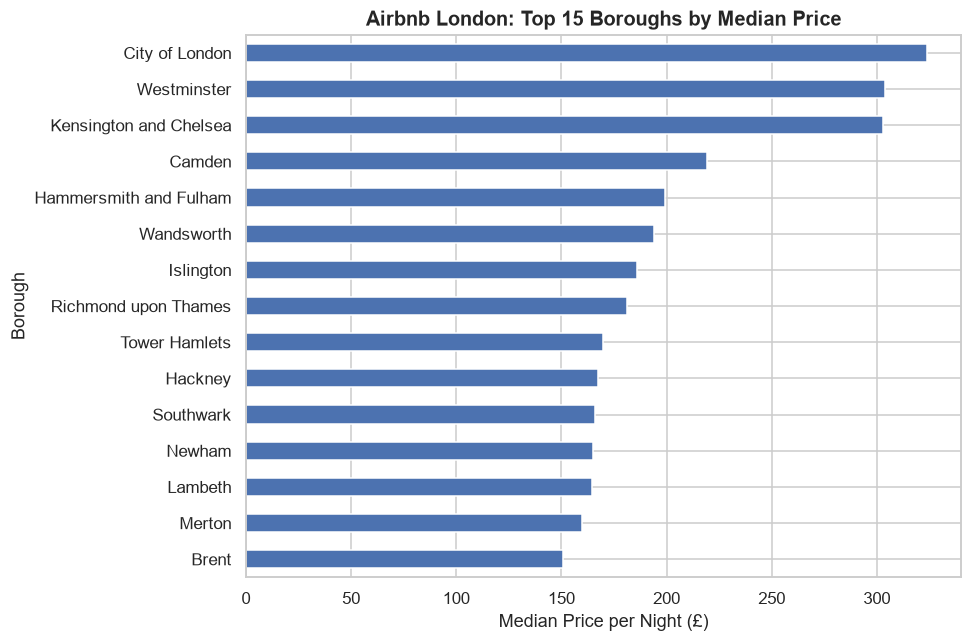

In [9]:
borough_price = (
    airbnb.groupby("neighbourhood_cleansed")["price"]
    .median()
    .sort_values(ascending=False)
    .head(15)
)

fig, ax = plt.subplots(figsize=(9, 6))
borough_price.sort_values().plot(kind="barh", ax=ax, color=sns.color_palette("deep")[0])
ax.set_title("Airbnb London: Top 15 Boroughs by Median Price")
ax.set_xlabel("Median Price per Night (£)")
ax.set_ylabel("Borough")
plt.tight_layout()
plt.show()

## 5. Calendar Unavailability Proxy Distribution — Airbnb

**Business question:** Which listings are in the highest demand, and
does demand concentrate in specific property types? This tells a host
(or Airbnb itself) where inventory is scarce relative to guest appetite
— directly actionable for pricing and marketing decisions.

**Chart chosen: Histogram with KDE overlay**
A histogram is the correct default for showing the distribution of a
single continuous variable (booked-day percentage across all listings),
and the KDE (density) overlay smooths out bin-width artifacts so the
underlying shape (e.g. bimodal: mostly-empty vs. mostly-booked listings)
is visible.

**Why not a boxplot:** a boxplot would summarize this into 5 numbers and
hide exactly the bimodal pattern (if present) that matters most for a
business reading — "are most listings rarely booked, or is demand
fairly evenly spread?" is a shape question, not a summary-statistic one.

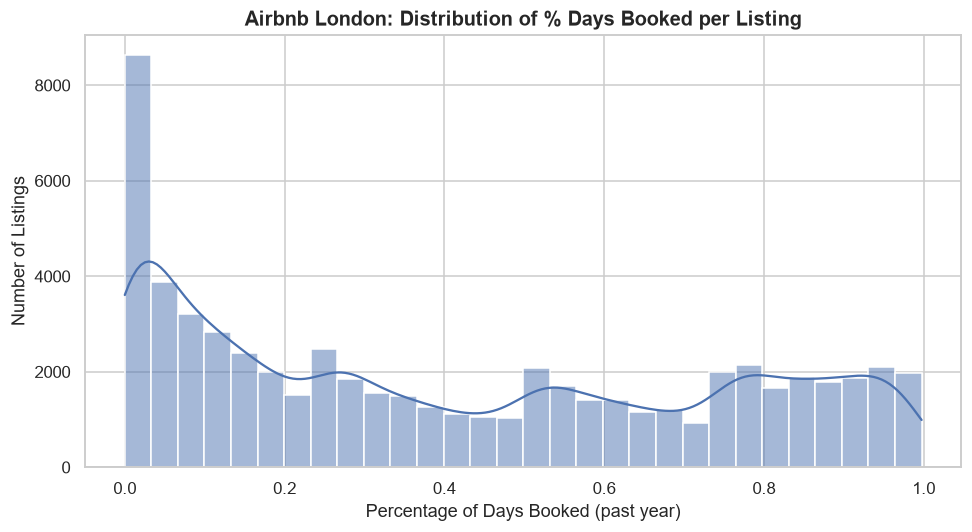

In [11]:
if "pct_days_booked" in airbnb.columns:
    fig, ax = plt.subplots()
    sns.histplot(airbnb["pct_days_booked"].dropna(), bins=30, kde=True, ax=ax)
    ax.set_title("Airbnb London: Distribution of % Days Booked per Listing")
    ax.set_xlabel("Percentage of Days Booked (past year)")
    ax.set_ylabel("Number of Listings")
    plt.tight_layout()
    plt.show()
else:
    print("pct_days_booked not available — calendar.csv in this export had no 'available' column. "
          "Revisit Step 2 of the cleaning pipeline if this signal is needed.")

## 6. Cross-Platform Summary Table

**Business question:** What's the single, decision-ready summary a
non-technical stakeholder (e.g. course faculty, or a hypothetical
business reader) would want, without reading every chart above?

**Format chosen: Summary table, not a chart**
Not every finding belongs in a chart. A compact table is the right
closing artifact here because the reader needs exact, precise, directly
comparable numbers across platforms — a chart would add visual noise
where precision is what's actually needed.

In [16]:
summary = comparison.groupby("platform").agg(
    n_records=("record_id", "count"),
    avg_price_gbp=("price_per_night_gbp", "mean"),
    avg_review_score=("review_score_0to10", "mean"),
    median_review_count=("review_count", "median"),
).round(2)

print(summary.to_string())

          n_records  avg_price_gbp  avg_review_score  median_review_count
platform                                                                 
airbnb        61617         241.07              9.34                  7.0
booking      262298            NaN              8.32                974.0


## Summary of EDA Findings

- Guest-perceived value ratings are lower on average across larger observed host portfolios in this snapshot: 4.713 for one-listing hosts versus 4.416 for 21+ listing hosts. This is an association, not evidence that portfolio size causes lower ratings. The distribution chart includes group counts and score spread.
- Price varies by room type and borough. These charts describe market context; they do not show that changing price will change value ratings.
- The listing-level price/rating scatter is exploratory and uses overall rating; it does not establish a causal price effect and is not the classifier's target.
- Calendar dates marked unavailable may reflect bookings, host blocks, or other reasons. The histogram is an unavailability proxy, not a verified demand measure.
- The cross-platform summary table is retained as context, but platform score comparisons are limited by different source periods and record grains.

**Model connection:** the value-rating classifier uses listing characteristics to prioritize profiles more likely to fall at or below the training-set lower-quartile value threshold. It supports aggregate, voluntary review only; it does not explain causes or judge individual hosts.
